# 06 Slantsy scenarios

This notebook estimates yearly visitors for the planned Research Institute and Museum of Geology in Slantsy, using the model calibrated in 05 (model C: location + heritage class).

**Location.** The new complex is on the Plyussa riverfront in the town centre, a short distance from the existing Slantsy museum, so the existing museum's travel times are used for it.

**Distance decay range.** The model is run at the central β and at the lowest and highest β from leave-one-out. For each β, k and the heritage effect are refitted on the 8 sites.

**What is modelled and what is added.** The gravity model covers day trips by car from St Petersburg, Leningrad Oblast and the border areas. Visitors to the research institute itself (conferences, student field groups, partner researchers) and long-distance tourists are not driven by population and distance, so they are added later as separate lines.

**Benchmark.** The closest real analogue is the Messel Pit in Germany (UNESCO fossil site in a former oil shale mine, with research on site and a visitor centre opened in 2010): about 30,000 visitors in 2023 and over 40,000 in 2025, against an original expectation of 100,000.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp

PROCESSED = "../data/processed"

origins = pd.read_csv(f"{PROCESSED}/origins.csv")
tt = pd.read_csv(f"{PROCESSED}/travel_times.csv").set_index("origin_id")
pop = origins.set_index("origin_id")["population"].reindex(tt.index)
P = pop.to_numpy()
params = pd.read_csv(f"{PROCESSED}/calibration_params.csv").set_index("model")
sites = pd.read_csv(f"{PROCESSED}/calibration_sites.csv", index_col="name_en")

# new complex: same town centre as the existing museum, so same travel times
NEW_SITE_PROXY = "Slantsy Local History Museum"
t_new = tt[[NEW_SITE_PROXY]].to_numpy()

T_cal = tt[sites.index].to_numpy()
y = np.log(sites["visitors"].to_numpy())
h = sites["heritage"].to_numpy().astype(float)

def log_access(beta, T):
    # log of sum_i P_i * exp(-beta * t_ij)
    return logsumexp(-beta * T, b=P[:, None], axis=0)

def fit_fixed_beta(beta):
    # with β fixed, log k and γ come from an ordinary linear regression
    X = np.column_stack([np.ones_like(h), h])
    coef, *_ = np.linalg.lstsq(X, y - log_access(beta, T_cal), rcond=None)
    return coef   # log_k, gamma

c = params.loc["C"]
rows = []
for label, b in [("slow decay (β low)", c["beta_low"]),
                 ("central", c["beta"]),
                 ("fast decay (β high)", c["beta_high"])]:
    lk, g = fit_fixed_beta(b)
    acc = log_access(b, t_new)[0]
    rows.append({"case": label, "beta": b, "halves_min": np.log(2) / b,
                 "heritage_x": np.exp(g),
                 "local_class": np.exp(lk + acc),
                 "heritage_class": np.exp(lk + g + acc)})
slantsy = pd.DataFrame(rows).set_index("case")

# check: the central row should match model C from 05
lk_c, g_c = fit_fixed_beta(c["beta"])
print(f"Check vs 05: log_k {lk_c:.4f} vs {c['log_k']:.4f}, gamma {g_c:.4f} vs {c['gamma']:.4f}")
slantsy.round({"beta": 4, "halves_min": 0, "heritage_x": 1, "local_class": 0, "heritage_class": 0})

Check vs 05: log_k -4.8241 vs -4.8241, gamma 2.1241 vs 2.1241


,beta,halves_min,heritage_x,local_class,heritage_class
case,,,,,
slow decay (β low),0.0120,58.0,8.6,4998.0,43031.0
central,0.0158,44.0,8.4,4305.0,36015.0
fast decay (β high),0.0189,37.0,8.2,3874.0,31800.0


## Scenarios

The new complex is treated as a **heritage-class** attraction: a purpose-built museum with research on site, an observation tower on the spoil heap and the Klint nearby, rather than a local history museum. How strongly it performs within that class is the main uncertainty, so the scenarios use the real spread of the four heritage sites:

- **Low:** performs like the weakest heritage site relative to its location.
- **Base:** a typical heritage site.
- **High:** performs like the strongest heritage site.

Each scenario is computed for the three distance-decay cases. The local-museum level is shown only as a reference: it is what the existing Slantsy museum already achieves.

In [2]:
# low / base / high for each decay case
heritage_names = sites.index[h == 1]
grid = []
for case, row in slantsy.iterrows():
    lk, g = fit_fixed_beta(row["beta"])
    pred_sites = np.exp(lk + g * h + log_access(row["beta"], T_cal))
    factor = sites["visitors"].to_numpy() / pred_sites
    fh = factor[h == 1]
    grid.append({"case": case,
                 "weakest": heritage_names[fh.argmin()], "f_low": fh.min(),
                 "strongest": heritage_names[fh.argmax()], "f_high": fh.max(),
                 "low": row["heritage_class"] * fh.min(),
                 "base": row["heritage_class"],
                 "high": row["heritage_class"] * fh.max()})
grid = pd.DataFrame(grid).set_index("case")

cen = grid.loc["central"]
print(f"Day trips by car, central decay: low {cen['low']:,.0f}, base {cen['base']:,.0f}, high {cen['high']:,.0f}")
print(f"Including decay range: {grid['low'].min():,.0f} to {grid['high'].max():,.0f}")
grid.round({"f_low": 2, "f_high": 2, "low": 0, "base": 0, "high": 0})

Day trips by car, central decay: low 19,113, base 36,015, high 64,791
Including decay range: 16,811 to 75,658


,weakest,f_low,strongest,f_high,low,base,high
case,,,,,,,
slow decay (β low),Koporye Fortress,0.53,Staraya Ladoga Museum-Reserve,1.76,23016.0,43031.0,75658.0
central,Koporye Fortress,0.53,Staraya Ladoga Museum-Reserve,1.80,19113.0,36015.0,64791.0
fast decay (β high),Koporye Fortress,0.53,Staraya Ladoga Museum-Reserve,1.83,16811.0,31800.0,58229.0


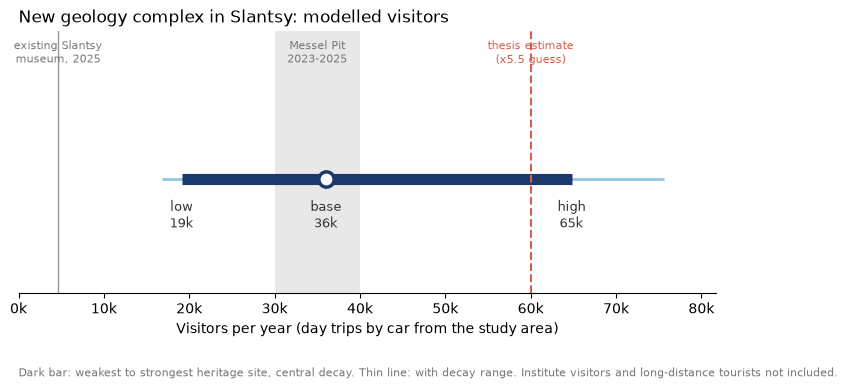

In [3]:
# summary chart
from matplotlib.ticker import FuncFormatter

lo_all, hi_all = grid["low"].min(), grid["high"].max()

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.axvspan(30000, 40000, color="#d9d9d9", alpha=0.6, lw=0)   # Messel 2023-2025
ax.hlines(1, lo_all, hi_all, color="#92c5de", lw=2)          # decay range
ax.hlines(1, cen["low"], cen["high"], color="#1b3a6b", lw=8)  # low to high, central decay
ax.plot(cen["base"], 1, "o", ms=11, color="white", mec="#1b3a6b", mew=2.5, zorder=3)
for x, txt in [(cen["low"], "low"), (cen["base"], "base"), (cen["high"], "high")]:
    ax.annotate(f"{txt}\n{x / 1000:.0f}k", (x, 1), xytext=(0, -14), textcoords="offset points",
                ha="center", va="top", fontsize=9, color="#333333")

ax.axvline(4645, color="#999999", lw=1)
ax.axvline(60000, color="#d6604d", lw=1.5, ls="--")
for x, txt, col in [(4645, "existing Slantsy\nmuseum, 2025", "#777777"),
                    (35000, "Messel Pit\n2023-2025", "#777777"),
                    (60000, "thesis estimate\n(x5.5 guess)", "#d6604d")]:
    ax.text(x, 1.68, txt, ha="center", va="top", fontsize=8, color=col)

ax.set_ylim(0.45, 1.72)
ax.set_xlim(0, hi_all * 1.08)
ax.set_yticks([])
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:g}k"))
ax.set_xlabel("Visitors per year (day trips by car from the study area)")
ax.set_title("New geology complex in Slantsy: modelled visitors", loc="left")
ax.text(0, -0.32, "Dark bar: weakest to strongest heritage site, central decay. Thin line: with decay range. "
        "Institute visitors and long-distance tourists not included.",
        transform=ax.transAxes, fontsize=8, color="#777777")
for s in ["left", "top", "right"]:
    ax.spines[s].set_visible(False)
fig.savefig("../figures/06_scenarios.png", dpi=200, bbox_inches="tight")
plt.show()